# Exercise 6: Training a CNN on CIFAR-10

This notebook starts with the code of the official PyTorch tutorial
[Training a Classifier](https://docs.pytorch.org/tutorials/beginner/blitz/cifar10_tutorial.html):
loading CIFAR-10, the network from the slides and the training loop.

**Task 1** is to get this running on your own computer. The **follow-up tasks** each ask you to change either the network or the training loop. You don't have to do all of them; pick the ones that interest you, but do Task 2 first, since the others need it.

Note: Every task from **Task 4** onward is considered as a bonus task. 

There are no asserts in this notebook. Each task has a **checkpoint** that tells you roughly what you should see. If your result is far off, compare with your neighbours.

Everything runs on a CPU. A GPU (or an Apple M-chip) makes it faster, see the bonus task at the end. Training the bigger networks takes several minutes: start a run and read the next task while it trains.

---
# Starter code (from the PyTorch tutorial)

## 1. Load and normalize CIFAR-10

The first run downloads the dataset (about 170 MB) into the folder `./data`.

**Note from the tutorial:** If you are running this on Windows or macOS and get a `BrokenPipeError` or a `RuntimeError` related to multiprocessing, set `num_workers=0` in the two `DataLoader`s.

In [1]:
#!aria2c -x 16 -s 16 -d ./data https://www.cs.toronto.edu/~kriz/cifar-10-python.tar.gz

In [2]:
import os
print(os.getcwd())
print(os.listdir('./data'))

/Users/jun/Library/CloudStorage/OneDrive-Personal/Uni/4. Semester/Data Mining & Machine Learning 2/Code/ml2-ws26
['cifar-10-python.tar.1.gz', 'cifar-10-batches-py', 'titanic.csv', 'cifar-10-python.tar.gz', 'cifar-10-python.tar.1.gz.aria2', 'openml']


In [3]:
import torch
import torchvision
from torchvision.transforms import v2

transform = v2.Compose([
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))])

batch_size = 4

trainset = torchvision.datasets.CIFAR10(root='./data', train=True,
                                        download=False, transform=transform)  # download=False: lädt nie neu
trainloader = torch.utils.data.DataLoader(trainset, batch_size=batch_size,
                                          shuffle=True, num_workers=0)

testset = torchvision.datasets.CIFAR10(root='./data', train=False,
                                       download=False, transform=transform)
testloader = torch.utils.data.DataLoader(testset, batch_size=batch_size,
                                         shuffle=False, num_workers=0)

classes = ('plane', 'car', 'bird', 'cat',
           'deer', 'dog', 'frog', 'horse', 'ship', 'truck')

In [4]:
batch = next(iter(trainloader))
print(type(batch))   # dict => das ist die Ursache

<class 'list'>


Let us show some of the training images:

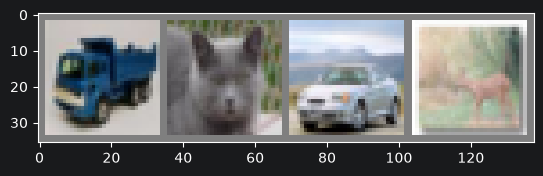

truck cat   car   deer 


In [5]:
import matplotlib.pyplot as plt
import numpy as np


def imshow(img):
    img = img / 2 + 0.5     # unnormalize
    npimg = img.numpy()
    plt.imshow(np.transpose(npimg, (1, 2, 0)))
    plt.show()


# get some random training images
dataiter = iter(trainloader)
images, labels = next(dataiter)

# show images
imshow(torchvision.utils.make_grid(images))
# print labels
print(' '.join(f'{classes[labels[j]]:5s}' for j in range(batch_size)))

## 2. Define a convolutional neural network

In [6]:
import torch.nn as nn
import torch.nn.functional as F


class Net(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 6, 5)
        self.pool = nn.MaxPool2d(2, 2)
        self.conv2 = nn.Conv2d(6, 16, 5)
        self.fc1 = nn.Linear(16 * 5 * 5, 120)
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, 10)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = torch.flatten(x, 1) # flatten all dimensions except batch
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = self.fc3(x)
        return x


net = Net()

## 3. Define a loss function and optimizer

In [7]:
import torch.optim as optim

criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(net.parameters(), lr=0.001, momentum=0.9)

## 4. Train the network

In [8]:
import time

In [9]:
start=time.time()

for epoch in range(2):  # loop over the dataset multiple times

    running_loss = 0.0
    for i, data in enumerate(trainloader, 0):
        # get the inputs; data is a list of [inputs, labels]
        inputs, labels = data

        # zero the parameter gradients
        optimizer.zero_grad()

        # forward + backward + optimize
        outputs = net(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        # print statistics
        running_loss += loss.item()
        if i % 2000 == 1999:    # print every 2000 mini-batches
            print(f'[{epoch + 1}, {i + 1:5d}] loss: {running_loss / 2000:.3f}')
            running_loss = 0.0

print('Finished Training')
print(f"Took {time.time() - start:.2f} second")

[1,  2000] loss: 2.208
[1,  4000] loss: 1.843
[1,  6000] loss: 1.683
[1,  8000] loss: 1.586
[1, 10000] loss: 1.540
[1, 12000] loss: 1.464
[2,  2000] loss: 1.401
[2,  4000] loss: 1.368
[2,  6000] loss: 1.330
[2,  8000] loss: 1.311
[2, 10000] loss: 1.291
[2, 12000] loss: 1.281
Finished Training
Took 56.22 second


---
# Task 1: Train the network on your computer

Run all cells above.

* How long does the training take on your computer? Measure it: put `start = time.time()` before the training loop and print `time.time() - start` after it (`import time` first).
* What is the loss of a network that guesses randomly among 10 classes? (Hint: cross-entropy of a uniform guess is −ln(1/10).) Is your network better?

**Checkpoint:** the loss starts around 2.3 and goes down clearly during the two epochs. On a laptop CPU the two epochs take a few minutes.

In [10]:
# your code
print(f"My loss 1.295 vs. random guess loss {-np.log(1/10)}")

My loss 1.295 vs. random guess loss 2.3025850929940455


# Task 2: How good is the network?

The training loss alone doesn't tell you how well the network classifies **new** images.

a) Write a function `evaluate(net, loader)` that returns the accuracy (fraction of correctly classified images) of `net` on all images of `loader`. Use it to compute the test accuracy of your trained network.

Hints: `torch.no_grad()` switches off gradient computation; the predicted class is the index of the largest output (`outputs.argmax(dim=1)`).

b) Which class does the network recognize best, which one worst? Compute the accuracy per class.

**Checkpoint:** clearly above 10% (random guessing); the PyTorch tutorial reports around 50% after 2 epochs.

In [11]:
def evaluate(net, loader):
    correct = 0
    total = 0
    with torch.no_grad():
        for inputs, labels in loader:
            outputs = net(inputs)
            preds = outputs.argmax(dim=1)
            correct += (preds == labels).sum().item()
            total += len(labels)
    return correct / total

In [12]:
evaluate(net, testloader)

0.531

In [13]:
def evaluate_per_class(net, loader):
    correct_per_class = [0] * 10
    total_per_class = [0] * 10
    with torch.no_grad():
        for inputs, labels in loader:
            outputs = net(inputs)
            preds = outputs.argmax(dim=1)
            for label, pred in zip(labels, preds):
                total_per_class[label] += 1
                if pred == label:
                    correct_per_class[label] += 1
    return correct_per_class, total_per_class

In [14]:
evaluate_per_class(net, testloader)   # loader = testloader

([544, 520, 425, 579, 373, 377, 575, 653, 775, 489],
 [1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000])

# Task 3: Larger batches

The tutorial uses `batch_size = 4`, so one epoch has 12,500 weight updates.

a) Change the batch size to 64 (you have to recreate the `DataLoader`s) and train a new network for 2 epochs. Compare training time and test accuracy with Task 1/2.

b) Your accuracy probably got worse. Try to fix it without going back to small batches, for example with a larger learning rate or more epochs.

**Checkpoint:** an epoch with batch size 64 is several times faster. With the same learning rate (0.001) the accuracy after 2 epochs drops clearly, because the network makes 16× fewer updates. A learning rate of about 0.01 brings it back.

In [33]:
batch_size = 64

trainloader2 = torch.utils.data.DataLoader(trainset, batch_size=batch_size,
                                          shuffle=True, num_workers=0)

testloader2 = torch.utils.data.DataLoader(testset, batch_size=batch_size,
                                         shuffle=False, num_workers=0)

In [34]:
class Net_2(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 6, 5)
        self.pool = nn.MaxPool2d(2, 2)
        self.conv2 = nn.Conv2d(6, 16, 5)
        self.fc1 = nn.Linear(16 * 5 * 5, 120)
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, 10)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = torch.flatten(x, 1) # flatten all dimensions except batch
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = self.fc3(x)
        return x


net2 = Net_2()

In [35]:
criterion2 = nn.CrossEntropyLoss()
optimizer2 = optim.SGD(net2.parameters(), lr=0.001, momentum=0.9)

In [41]:
start=time.time()

for epoch in range(2):  # loop over the dataset multiple times

    running_loss = 0.0
    for i, data in enumerate(trainloader2, 0):
        # get the inputs; data is a list of [inputs, labels]
        inputs, labels = data

        # zero the parameter gradients
        optimizer2.zero_grad()

        # forward + backward + optimize
        outputs = net2(inputs)
        loss = criterion2(outputs, labels)
        loss.backward()
        optimizer2.step()

        # print statistics
        running_loss += loss.item()
        if i % 2000 == 1999:    # print every 2000 mini-batches
            print(f'[{epoch + 1}, {i + 1:5d}] loss: {running_loss / 2000:.3f}')
            running_loss = 0.0

print('Finished Training')
print(f"Took {time.time() - start:.2f} second")

Finished Training
Took 28.56 second


In [42]:
evaluate_per_class(net2, testloader2)

([569, 677, 329, 284, 360, 588, 695, 650, 735, 630],
 [1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000])

In [43]:
evaluate(net2, testloader2)

0.5517

In [40]:
optimizer2 = optim.SGD(net2.parameters(), lr=0.01, momentum=0.9)

# Task 4: Watch the training: learning curves and overfitting

So far we only know the accuracy at the very end. Change the training so that you can see how the network develops.

a) Split 5,000 images off the training set as a **validation set** (`torch.utils.data.random_split`). From now on, compare models on the validation set; the test set is only for the very end.

b) Change the training loop so that it records the average training loss and the validation accuracy **after every epoch**. Train for 10 epochs and plot both curves. (With batch size 64 and the small network this takes a few minutes.)

c) Also record the training accuracy. Do training and validation accuracy drift apart? From which epoch on would you stop training?

**Checkpoint:** the validation accuracy rises quickly in the first epochs and then flattens out, while the training accuracy keeps rising. The growing gap is overfitting.

In [49]:
# a) 5000 Bilder vom Trainingsset abspalten (Seed, damit der Split reproduzierbar ist)
train_sub, val_sub = torch.utils.data.random_split(
    trainset, [45000, 5000], generator=torch.Generator().manual_seed(42))

batch_size = 64
train_loader = torch.utils.data.DataLoader(train_sub, batch_size=batch_size, shuffle=True, num_workers=0)
val_loader = torch.utils.data.DataLoader(val_sub, batch_size=batch_size, shuffle=False, num_workers=0)

Epoche 1: loss 1.923 | train acc 0.441 | val acc 0.432
Epoche 2: loss 1.452 | train acc 0.483 | val acc 0.472
Epoche 3: loss 1.291 | train acc 0.581 | val acc 0.553
Epoche 4: loss 1.197 | train acc 0.618 | val acc 0.585
Epoche 5: loss 1.116 | train acc 0.636 | val acc 0.591
Epoche 6: loss 1.053 | train acc 0.656 | val acc 0.595
Epoche 7: loss 0.988 | train acc 0.686 | val acc 0.615
Epoche 8: loss 0.947 | train acc 0.688 | val acc 0.604
Epoche 9: loss 0.913 | train acc 0.698 | val acc 0.605
Epoche 10: loss 0.861 | train acc 0.741 | val acc 0.631


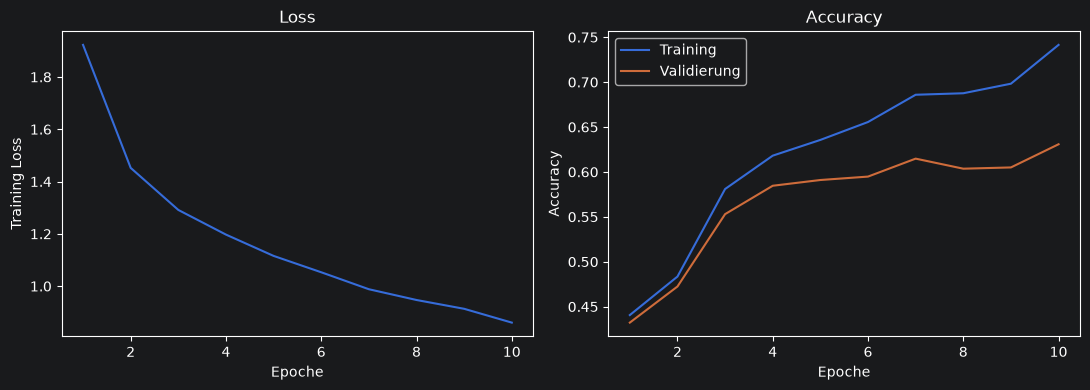

In [50]:
net = Net()
criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(net.parameters(), lr=0.01, momentum=0.9)

# b) + c) Training mit Aufzeichnung pro Epoche
epochs = 10
train_losses, train_accs, val_accs = [], [], []

for epoch in range(epochs):
    running_loss = 0.0
    for inputs, labels in train_loader:
        optimizer.zero_grad()
        loss = criterion(net(inputs), labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()

    train_losses.append(running_loss / len(train_loader))  # Ø Loss über alle Batches
    train_accs.append(evaluate(net, train_loader))         # Accuracy auf Trainingsdaten
    val_accs.append(evaluate(net, val_loader))             # Accuracy auf Validierungsdaten
    print(f"Epoche {epoch+1}: loss {train_losses[-1]:.3f} | "
          f"train acc {train_accs[-1]:.3f} | val acc {val_accs[-1]:.3f}")

# Plot: Loss und Accuracy
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
x = range(1, epochs + 1)

ax1.plot(x, train_losses)
ax1.set_xlabel("Epoche"); ax1.set_ylabel("Training Loss"); ax1.set_title("Loss")

ax2.plot(x, train_accs, label="Training")
ax2.plot(x, val_accs, label="Validierung")
ax2.set_xlabel("Epoche"); ax2.set_ylabel("Accuracy"); ax2.set_title("Accuracy")
ax2.legend()

plt.tight_layout()
plt.show()

# Task 5: A wider network

The network from the tutorial has only 6 and 16 filters.

a) Increase the number of filters to 32 in `conv1` and 64 in `conv2`. Which other layer do you have to change, and why? Train it like in Task 4, but for 5 epochs to save time.

b) Compare with the original network: validation accuracy, number of parameters (`sum(p.numel() for p in net.parameters())`) and training time. Where did the additional parameters end up?

**Checkpoint:** the wider network reaches a clearly higher validation accuracy, but each epoch takes noticeably longer. Most of the additional parameters sit in `fc1`.

In [23]:
# your code

# Task 6: A deeper network with 3×3 filters

Modern CNNs use small 3×3 filters with padding and stack more conv layers.

Build a network with **four** conv layers with 3×3 filters and `padding=1`, and a max pooling layer after every second conv layer, for example with 16, 16, 32, 32 filters. (More filters work better, but training gets slow on a CPU.) Compute the input size of the first fully connected layer **on paper first** (like on the exercise sheet), then check it by running the network.

Train it for 5 epochs and compare with Task 5.

**Checkpoint:** after the two poolings the feature maps are 8×8, so `fc1` gets 32·8·8 = 2048 inputs. The deeper network should beat the original network on the validation set.

In [24]:
# your code

# Task 7: A different optimizer

Replace SGD in your training loop by the Adam optimizer (`optim.Adam`, learning rate 0.001) and train one of your networks again. Does it learn faster in the first epochs? Is the final validation accuracy better?

**Checkpoint:** Adam usually reaches a good accuracy in fewer epochs than SGD with these settings; the final accuracy is similar.

In [25]:
# your code

# Task 8: Fighting overfitting

Your bigger networks overfit after a few epochs. Try one or more of the following (all not on the slides, look them up in the PyTorch documentation) and see whether the gap between training and validation accuracy gets smaller:

* **Data augmentation:** use a separate transform for the training set with `v2.RandomHorizontalFlip()` and `v2.RandomCrop(32, padding=4)`. The validation and test sets keep the original transform. Careful: with `random_split` both subsets share the transform of `trainset`, so you need a second `CIFAR10` object for the training data.
* **Dropout:** `nn.Dropout(0.5)` before the fully connected layers.
* **Batch normalization:** `nn.BatchNorm2d` after each conv layer.

**Checkpoint:** with data augmentation the training accuracy stays much closer to the validation accuracy, and the validation accuracy keeps rising for more epochs.

In [26]:
# your code

# Task 9: Training on a GPU

If your computer has an NVIDIA GPU or an Apple M-chip, you can train on it. Change your training loop as in the
[GPU section of the tutorial](https://docs.pytorch.org/tutorials/beginner/blitz/cifar10_tutorial.html#training-on-gpu):

```python
device = torch.device(torch.accelerator.current_accelerator().type if torch.accelerator.is_available() else 'cpu')
net.to(device)
inputs, labels = inputs.to(device), labels.to(device)   # inside the loop
```

Compare the time per epoch for the small `Net` and for your largest network. For which one is the speed-up bigger, and why?

---
# Final step: your best model on the test set

Take the model with the best **validation** accuracy and evaluate it **once** on the test set. Write down your result and compare with your neighbours:

* Which change brought the largest improvement?
* Which change cost the most training time?
* Is your test accuracy close to the validation accuracy?

In [27]:
# your code